# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Annie Nguyen, Sritha Alluri, Anh Bach

**Date:** 11/9/2026

In [3]:
# Your Phase 1 solution to the problem goes here.

# Question 1: Cleaning data and performing EDA & Visualization

Shape: (16814, 19)

First 5 rows:
 sale_date  sale_price  house_square_feet  attic_finished_square_feet  basement_square_feet  attached_garage_square_feet  detached_garage_square_feet  fireplaces       hvac_description     exterior interior  stories          roof_cover  year_built  bedrooms  bathrooms waterfront_type view_quality          utility_sewer
2020-01-02      380000               2157                           0                     0                          528                            0           0 Warm and Cool Air Zone Frame Siding  Drywall        2 Composition Shingle        1993         3          3             NaN          NaN SEWER/SEPTIC INSTALLED
2020-01-02      383000               2238                           0                     0                          396                            0           0             Forced Air Frame Siding  Drywall        2 Composition Shingle        2017         4          3             NaN          NaN SEWER/SEPTIC INSTALLED
202

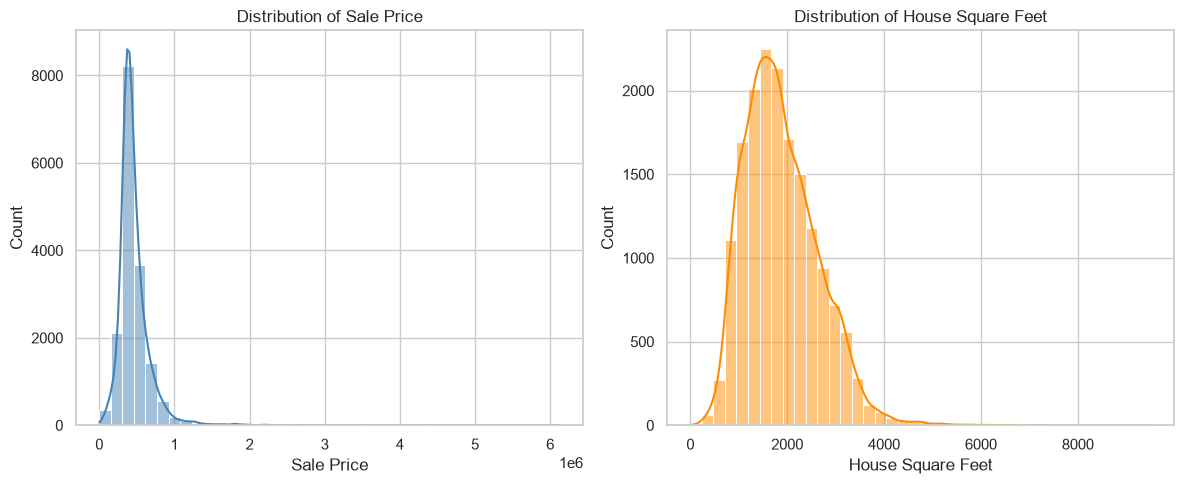

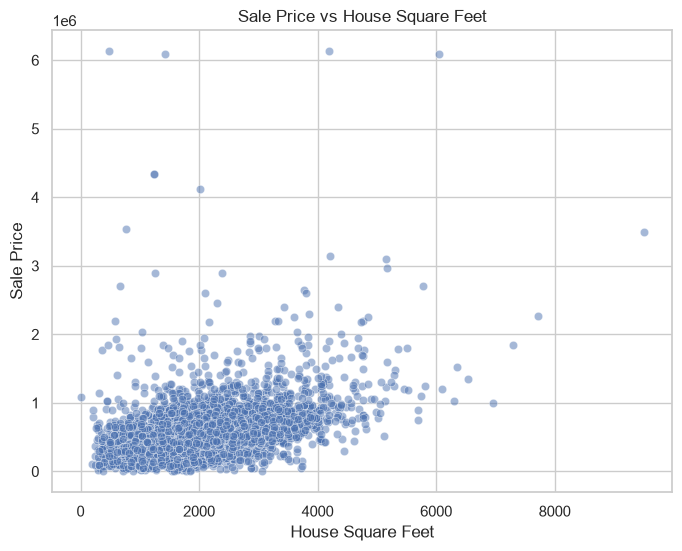

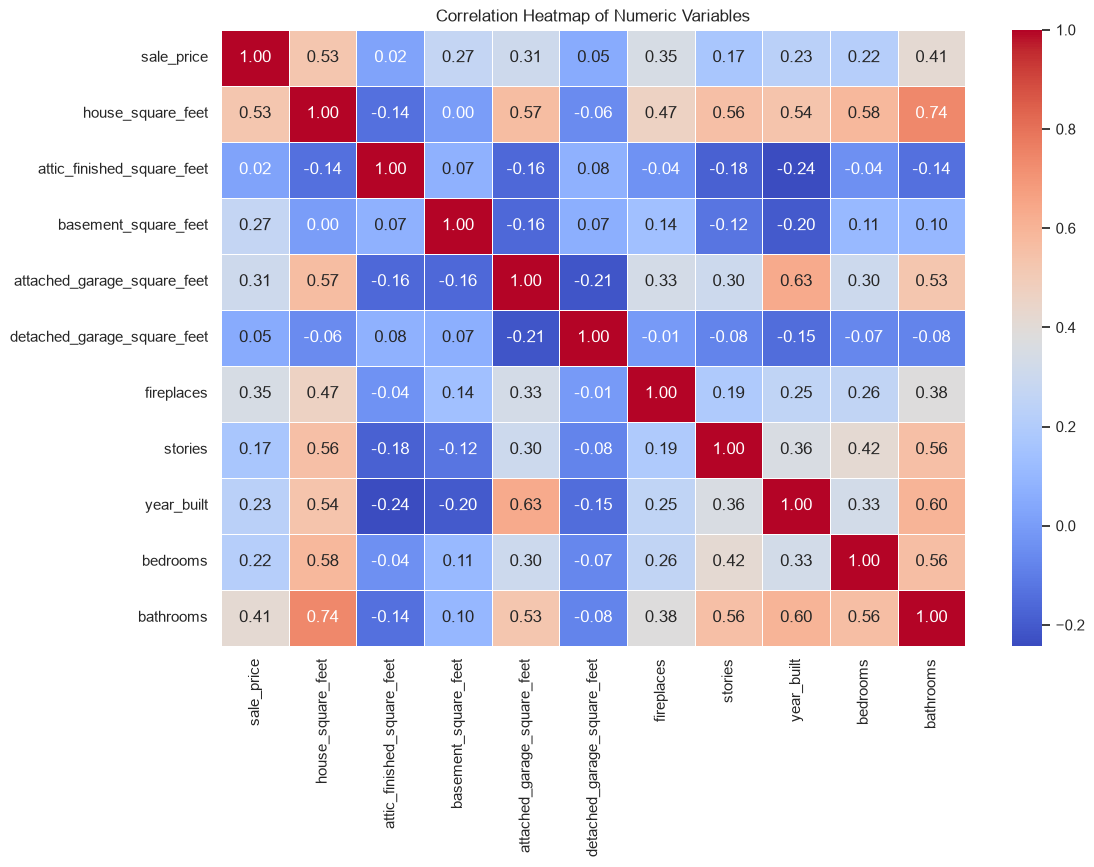

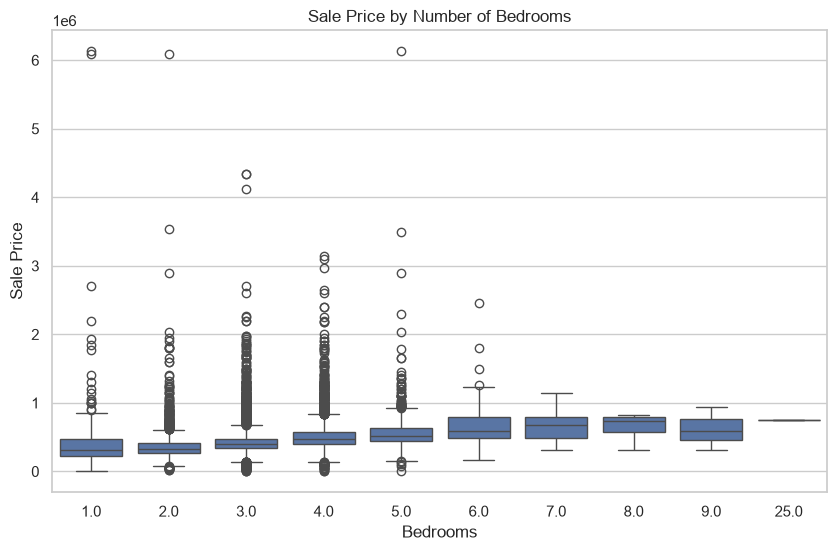

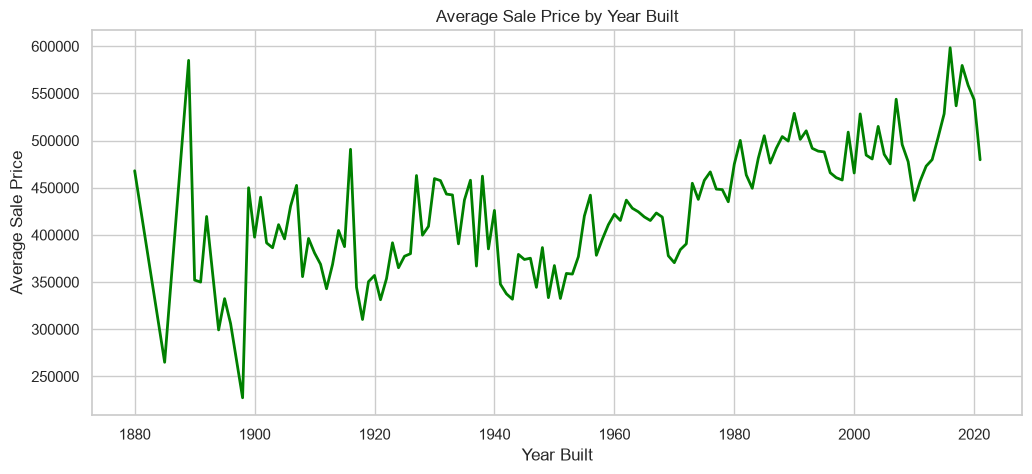

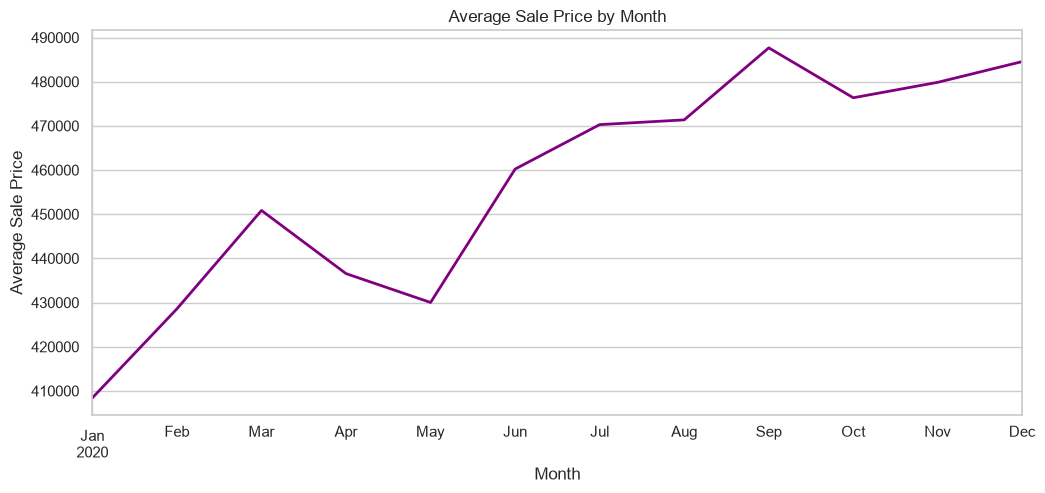


Top HVAC descriptions:
hvac_description
Forced Air                10345
Electric Baseboard         2663
Heat Pump                  2081
Warm and Cool Air Zone     1267
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
Unknown                       7
Electric                      2
Floor Wall Furnace            1

Top exterior materials:
exterior
Frame Siding              14536
Frame Vinyl                1719
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       43
Finished Cottage             41
Frame Rustic Log             21
Log                          12
Frame Hardboard              11
Cedar Finished Cabin          5

Outlier count in sale_price: 1008


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3.0,3.0,Unknown,Unknown,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4.0,3.0,Unknown,Unknown,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3.0,2.0,Unknown,Unknown,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2.0,1.0,Unknown,Unknown,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3.0,2.0,Unknown,Unknown,SEWER/SEPTIC INSTALLED


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset from the data folder
data_path = Path("data") / "pierce_county_house_sales.csv"
df = pd.read_csv(data_path)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))
print("\nMissing values before cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(20).to_string())

df = df.copy()
df["sale_date"] = pd.to_datetime(df["sale_date"], errors="coerce")
df = df.drop_duplicates().reset_index(drop=True)

for col in ["bedrooms", "bathrooms"]:
    df.loc[df[col] <= 0, col] = np.nan

# Fill categorical missing values with "Unknown"
cat_cols = [
    "hvac_description",
    "exterior",
    "interior",
    "roof_cover",
    "waterfront_type",
    "view_quality",
    "utility_sewer"
]

for col in cat_cols:
    df[col] = df[col].fillna("Unknown")

# Fill numeric missing values with medians
for col in ["bedrooms", "bathrooms", "year_built"]:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing values after cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(20).to_string())
print("\nNumeric summary:")
print(df.describe().T.to_string())

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df["sale_price"], bins=40, kde=True, color="steelblue")
plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
sns.histplot(df["house_square_feet"], bins=40, kde=True, color="darkorange")
plt.title("Distribution of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="house_square_feet", y="sale_price", alpha=0.5)
plt.title("Sale Price vs House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price")
plt.show()

numeric_df = df.select_dtypes(include=["number"])
corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="bedrooms", y="sale_price")
plt.title("Sale Price by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Sale Price")
plt.show()

yearly_avg = df.groupby("year_built")["sale_price"].mean().sort_index()
plt.figure(figsize=(12, 5))
yearly_avg.plot(kind="line", linewidth=2, color="green")
plt.title("Average Sale Price by Year Built")
plt.xlabel("Year Built")
plt.ylabel("Average Sale Price")
plt.show()

monthly_avg = (
    df.assign(month=df["sale_date"].dt.to_period("M"))
      .groupby("month")["sale_price"]
      .mean()
)
plt.figure(figsize=(12, 5))
monthly_avg.plot(kind="line", linewidth=2, color="purple")
plt.title("Average Sale Price by Month")
plt.xlabel("Month")
plt.ylabel("Average Sale Price")
plt.show()

# Distribution of major categorical features
print("\nTop HVAC descriptions:")
print(df["hvac_description"].value_counts().head(10).to_string())

print("\nTop exterior materials:")
print(df["exterior"].value_counts().head(10).to_string())

# Outlier check for sale price
Q1 = df["sale_price"].quantile(0.25)
Q3 = df["sale_price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["sale_price"] < lower_bound) | (df["sale_price"] > upper_bound)]
print(f"\nOutlier count in sale_price: {len(outliers)}")
df.head()

# Question 2: Transforming Variables

In [5]:
# Make numeric features from the sale date
df["sale_year"] = df["sale_date"].dt.year
df["sale_month"] = df["sale_date"].dt.month

# Separate the target (what we want to predict) from the predictors
y = df["sale_price"]
X = df.drop(columns=["sale_price", "sale_date"])

# Convert categorical variables into numeric indicator columns.
categorical_cols = X.select_dtypes(include=["object", "string", "category"]).columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Predictor matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nAll predictor columns are numeric:", X.select_dtypes(exclude="number").empty)
print("\nFirst five rows of transformed predictors:")
display(X.head())

Predictor matrix shape: (16768, 61)
Target shape: (16768,)

All predictor columns are numeric: True

First five rows of transformed predictors:


,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms,...,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good,utility_sewer_SEWER/SEPTIC AVAIL,utility_sewer_SEWER/SEPTIC INSTALLED,utility_sewer_SEWER/SEPTIC NO,utility_sewer_SEWER/SEPTIC NO PERC
0,2157,0,0,528,0,0,2,1993,3.0,3.0,...,0,0,0,0,0,0,0,1,0,0
1,2238,0,0,396,0,0,2,2017,4.0,3.0,...,0,0,0,0,0,0,0,1,0,0
2,1452,0,0,0,0,1,1,1965,3.0,2.0,...,0,0,0,0,0,0,0,1,0,0
3,832,0,0,0,0,0,1,1919,2.0,1.0,...,0,0,0,0,0,0,0,1,0,0
4,1780,0,384,484,0,1,1,1955,3.0,2.0,...,0,0,0,0,0,0,0,1,0,0


# Question 3: Implement an 80/20 train-test split

In [6]:
from sklearn.model_selection import train_test_split

# Split predictors and target into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training predictors: (13414, 61)
Test predictors: (3354, 61)
Training target: (13414,)
Test target: (3354,)


# Question 4: Fit and compare simple linear models
The model with all the predictors did the best; it had the lowest test RMSE ($153,486) and the highest test R^2 (0.522) of the four models. 

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

numeric_features = [
    "house_square_feet",
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
    "stories",
    "year_built",
    "bedrooms",
    "bathrooms",
    "sale_year",
    "sale_month",
]

numeric_features = [col for col in numeric_features if col in X_train.columns]

model_features = {
    "House size only": ["house_square_feet"],
    "Core features": [
        "house_square_feet",
        "bedrooms",
        "bathrooms",
        "year_built",
        "stories",
    ],
    "All numeric features": numeric_features,
    "All predictors (including categories)": list(X_train.columns),
}

results = []

for model_name, features in model_features.items():
    features = [col for col in features if col in X_train.columns]

    model = LinearRegression()
    model.fit(X_train[features], y_train)

    train_predictions = model.predict(X_train[features])
    test_predictions = model.predict(X_test[features])

    results.append({
        "Model": model_name,
        "Number of predictors": len(features),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_predictions)),
        "Train R²": r2_score(y_train, train_predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "Test R²": r2_score(y_test, test_predictions),
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE")
display(results_df.round(3))

,Model,Number of predictors,Train RMSE,Train R²,Test RMSE,Test R²
3,All predictors (including categories),61,158626.640,0.561,153485.710,0.522
2,All numeric features,12,184567.413,0.406,170416.737,0.411
1,Core features,5,196695.923,0.325,182214.927,0.326
0,House size only,1,203540.166,0.278,189646.864,0.270


# Question 5: Partial correlation plots 
We noticed that the plots expressed some nonlinearity, for features such as: square footages, year built, and stories. However, the trends in the plots were very close to linear. 

c:\Users\annie\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_polynomial_impl.py:676: RuntimeWarning: invalid value encountered in divide
  lhs /= scale


LinAlgError: SVD did not converge in Linear Least Squares

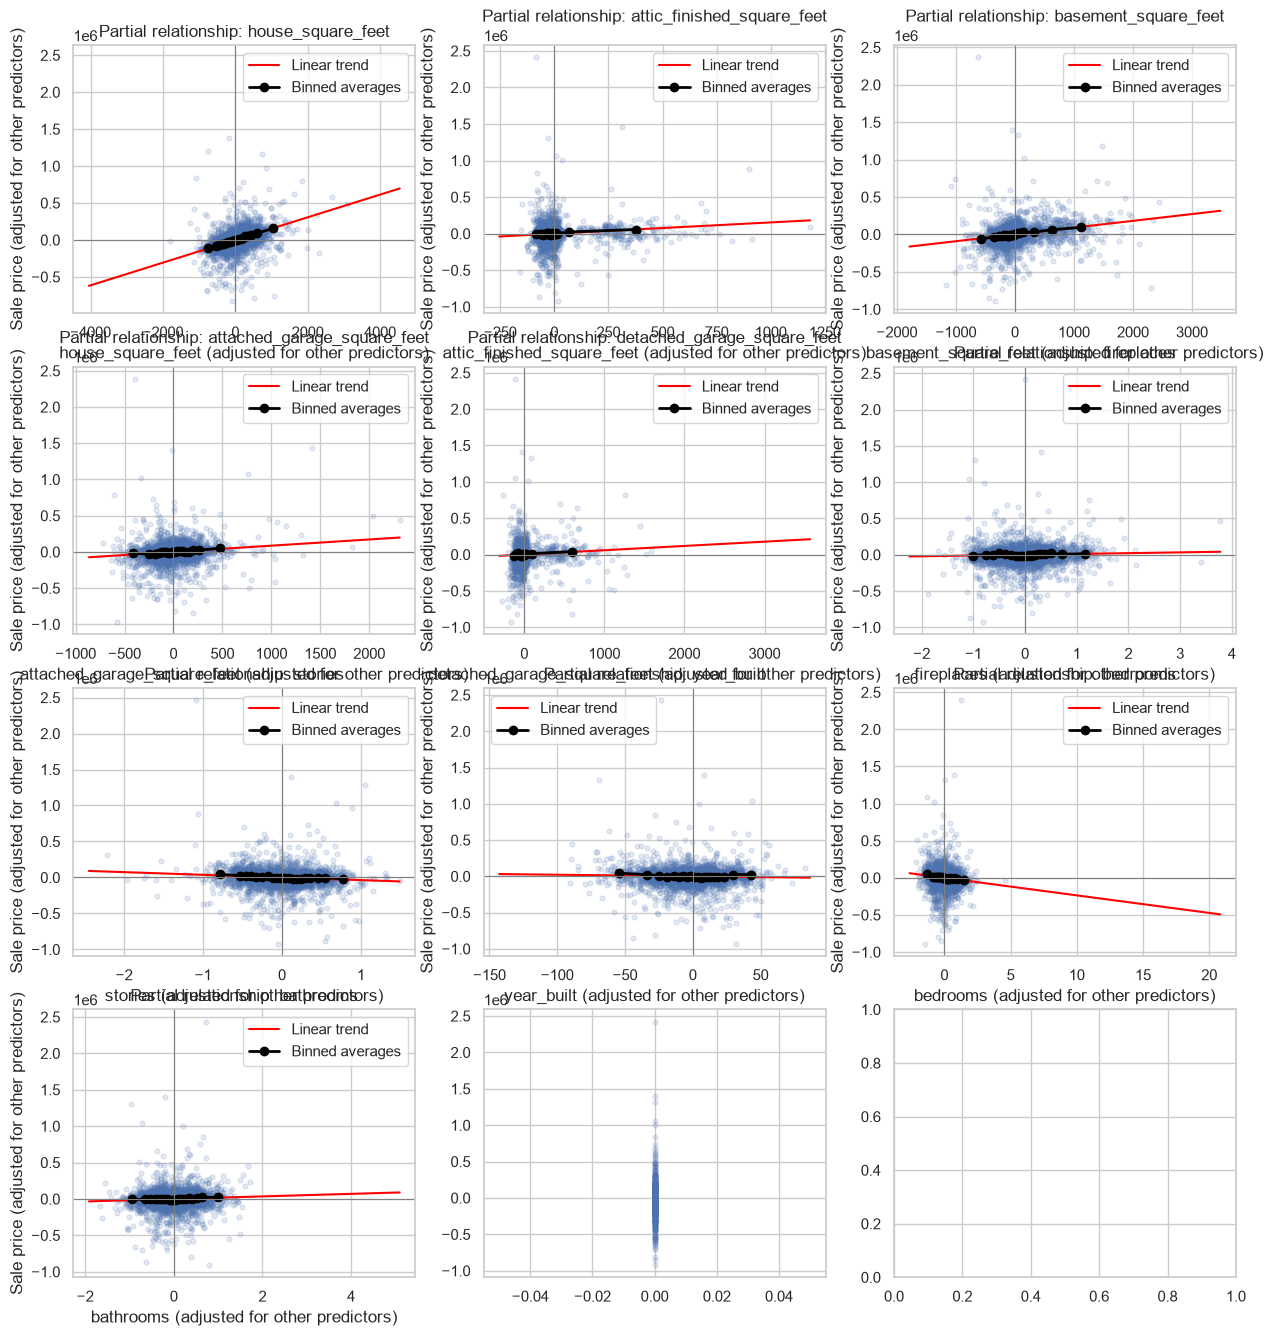

In [8]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

numeric_features = [
    "house_square_feet",
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
    "stories",
    "year_built",
    "bedrooms",
    "bathrooms",
    "sale_year",
    "sale_month",
]

numeric_features = [col for col in numeric_features if col in X_train.columns]
all_features = list(X_train.columns)

ncols = 3
nrows = math.ceil(len(numeric_features) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).reshape(-1)

for i, feature in enumerate(numeric_features):
    other_features = [col for col in all_features if col != feature]

    y_model = LinearRegression().fit(X_train[other_features], y_train)
    y_residual = y_train - y_model.predict(X_train[other_features])

    x_model = LinearRegression().fit(
        X_train[other_features],
        X_train[feature]
    )
    x_residual = X_train[feature] - x_model.predict(X_train[other_features])

    partial_data = pd.DataFrame({
        "x_residual": np.asarray(x_residual),
        "y_residual": np.asarray(y_residual),
    })

    points = partial_data.sample(
        n=min(3000, len(partial_data)),
        random_state=42
    )
    axes[i].scatter(
        points["x_residual"],
        points["y_residual"],
        alpha=0.15,
        s=12,
        label="Observations"
    )

    x_values = partial_data["x_residual"].to_numpy(dtype=float)
    y_values = partial_data["y_residual"].to_numpy(dtype=float)
    valid = np.isfinite(x_values) & np.isfinite(y_values)
    x_values = x_values[valid]
    y_values = y_values[valid]

    x_scale = max(1.0, np.max(np.abs(x_values))) if len(x_values) else 1.0
    has_variation = (
        len(x_values) > 1
        and np.ptp(x_values) > np.finfo(float).eps * x_scale
    )

    if has_variation:
        slope, intercept = np.polyfit(x_values, y_values, 1)
        x_line = np.linspace(x_values.min(), x_values.max(), 100)
        axes[i].plot(
            x_line,
            slope * x_line + intercept,
            color="red",
            label="Linear trend"
        )

        plot_data = pd.DataFrame({
            "x_residual": x_values,
            "y_residual": y_values
        })
        plot_data["bin"] = pd.qcut(
            plot_data["x_residual"],
            q=20,
            duplicates="drop"
        )
        binned = plot_data.groupby("bin", observed=True).agg(
            x_mean=("x_residual", "mean"),
            y_mean=("y_residual", "mean")
        )
        axes[i].plot(
            binned["x_mean"],
            binned["y_mean"],
            color="black",
            marker="o",
            linewidth=2,
            label="Binned averages"
        )
    else:
        axes[i].text(
            0.5,
            0.95,
            "No variation in adjusted predictor",
            transform=axes[i].transAxes,
            ha="center",
            va="top"
        )

    axes[i].axhline(0, color="gray", linewidth=0.8)
    axes[i].axvline(0, color="gray", linewidth=0.8)
    axes[i].set_title(f"Partial relationship: {feature}")
    axes[i].set_xlabel(f"{feature} (adjusted for other predictors)")
    axes[i].set_ylabel("Sale price (adjusted for other predictors)")
    if has_variation:
        axes[i].legend()

for i in range(len(numeric_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]